# P2.2 · MLP on FashionMNIST (+ confusion matrix by hand)

**ID:** P2.2 · **Target:** 25 min · **Plan week:** 1 (and timed repeat in week 2) · **Part:** P (PyTorch first principles)

**The drill.** From a blank notebook, train a 10-class MLP on FashionMNIST (28×28 grey clothing images, 60k train /
10k test) using the P0 skeleton, and do the error analysis with a confusion matrix you compute yourself.

**Must include (from the plan):** `DataLoader`, `CrossEntropyLoss`, val accuracy, confusion matrix, initial-loss
check. Also: a val split carved out of train (test touched once), normalization with train statistics, overfit-one-
batch, eval aggregated over the whole set under `model.eval()` + `torch.no_grad()`. The confusion matrix is built
**by hand with `torch.bincount`** and checked against `sklearn.metrics.confusion_matrix`.

**Rules.** No docs, no LLM. Each solution cell keeps only its spec (comments). The data is pre-downloaded:
always pass `download=False`. The self-check cell names the variables it expects.

## Sources
- H. Xiao, K. Rasul, R. Vollgraf, *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning
  Algorithms*, 2017, arXiv:1708.07747 — https://arxiv.org/abs/1708.07747 (dataset, class names).
- zalandoresearch/fashion-mnist README, "Benchmark" table of submitted results (MLP 256-128-100: 0.883; small
  2-3 conv-layer CNNs: 0.90-0.94), commit b2617bb: https://github.com/zalandoresearch/fashion-mnist/blob/b2617bb6d3ffa2e429640350f613e3291e10b141/README.md
- PyTorch *Learn the Basics* tutorial (it uses FashionMNIST end to end; BSD-3):
  https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
- pytorch/examples `mnist/main.py` (eval loop summing `reduction='sum'` losses and correct counts over the whole
  test set), commit acc295d, BSD-3: https://github.com/pytorch/examples/blob/acc295dc7b90714f1bf47f06004fc19a7fe235c4/mnist/main.py
- torchvision `FashionMNIST` dataset docs: https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html
- scikit-learn `confusion_matrix` (rows = true label, columns = predicted; the reference for the check):
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
- A. Karpathy, *A Recipe for Training Neural Networks* (2019), "verify loss @ init", "overfit one batch":
  https://karpathy.github.io/2019/04/25/recipe/

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

from prep import DATA, Session, check, check_close, seed_everything

s = Session("P2.2", target_min=25)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

[P2.2] started 16:41; target 25 min


In [2]:
# 1. DATA. torchvision.datasets.FashionMNIST(DATA, train=True / False, download=False).
#    Take the raw uint8 tensors `.data` (N, 28, 28) and `.targets` (N,). Inspect dtype, range, class counts.
#    Convert to float in [0, 1] and flatten to (N, 784).
#    Val split: a seeded permutation (torch.Generator().manual_seed(0)) of the 60k train images ->
#    last 5000 = val, first 55000 = train.
#    Normalize with ONE scalar mean/std computed on the 55k train images only -> `mu`, `sd` (python floats).
#    Final tensors: X_train, y_train, X_val, y_val, X_test, y_test (float32 X, int64 y).
tr = torchvision.datasets.FashionMNIST(DATA, train=True, download=False)
te = torchvision.datasets.FashionMNIST(DATA, train=False, download=False)
print(tr.data.shape, tr.data.dtype, tr.data.min().item(), tr.data.max().item(), "classes", torch.bincount(tr.targets).tolist())
X_all = tr.data.float().div(255).reshape(-1, 784)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
tr_idx, va_idx = perm[:55000], perm[55000:]
mu, sd = X_all[tr_idx].mean().item(), X_all[tr_idx].std().item()
print(f"train mean {mu:.4f} std {sd:.4f}")
norm = lambda x: (x - mu) / sd
X_train, y_train = norm(X_all[tr_idx]), tr.targets[tr_idx]
X_val, y_val = norm(X_all[va_idx]), tr.targets[va_idx]
X_test, y_test = norm(te.data.float().div(255).reshape(-1, 784)), te.targets
print(X_train.shape, X_val.shape, X_test.shape, y_train.dtype)

torch.Size([60000, 28, 28]) torch.uint8 0 255 classes [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]
train mean 0.2863 std 0.3532


torch.Size([55000, 784]) torch.Size([5000, 784]) torch.Size([10000, 784]) torch.int64


In [3]:
# 2. DATALOADERS. TensorDataset + DataLoader: train batch 128 shuffle=True; val/test batch 1024 shuffle=False.
#    Pull one batch and print its shapes/dtypes.
train_dl = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_dl = DataLoader(TensorDataset(X_val, y_val), batch_size=1024)
test_dl = DataLoader(TensorDataset(X_test, y_test), batch_size=1024)
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

torch.Size([128, 784]) torch.float32 torch.Size([128]) torch.int64


In [4]:
# 3. MODEL + LOSS + OPTIMIZER. `MLP`: 784 -> 256 -> 128 -> 10, ReLU, Dropout(0.2) after each hidden layer,
#    raw logits (B, 10). `make_model()` -> fresh model on `dev`. Print the parameter count.
#    loss_fn = nn.CrossEntropyLoss(); opt = AdamW(lr=1e-3, weight_decay=1e-2).
class MLP(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(p),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


def make_model():
    return MLP().to(dev)


model = make_model()
print(sum(p.numel() for p in model.parameters()), "params")
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

235146 params


In [5]:
# 4. EVAL. `evaluate(model, dl) -> (mean loss, accuracy)` over the whole set (model.eval(), no_grad,
#    loss summed with reduction="sum" or weighted by batch size, then / N).
#    `predict(model, dl) -> (preds, targets)`: argmax predictions and targets for the whole set, on CPU.
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    tot, correct, n = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = model(xb)
        tot += nn.functional.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return tot / n, correct / n


@torch.no_grad()
def predict(model, dl):
    model.eval()
    ps, ys = [], []
    for xb, yb in dl:
        ps.append(model(xb.to(dev)).argmax(1).cpu())
        ys.append(yb)
    return torch.cat(ps), torch.cat(ys)

In [6]:
# 5. SANITY CHECKS. (a) `init_loss` = val loss of the untrained `model`; compare with ln 10.
#    (b) Overfit one batch of 64 train images with a fresh model in eval mode (dropout off), AdamW lr=1e-3,
#        200 steps -> `overfit_loss` (should be < 0.05).
init_loss, init_acc = evaluate(model, val_dl)
print(f"init loss {init_loss:.3f} (ln10 = {math.log(10):.3f}), init acc {init_acc:.3f}")
tmp = make_model().eval()
tmp_opt = torch.optim.AdamW(tmp.parameters(), lr=1e-3)
xb, yb = X_train[:64].to(dev), y_train[:64].to(dev)
for _ in range(200):
    loss = loss_fn(tmp(xb), yb)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_loss = loss.item()
print(f"overfit-one-batch loss {overfit_loss:.4f}")

init loss 2.292 (ln10 = 2.303), init acc 0.157


overfit-one-batch loss 0.0001


epoch  1 train 0.539 val 0.397 acc 0.8482


epoch  2 train 0.390 val 0.370 acc 0.8610


epoch  3 train 0.354 val 0.330 acc 0.8742


epoch  4 train 0.328 val 0.319 acc 0.8802


epoch  5 train 0.311 val 0.310 acc 0.8824


epoch  6 train 0.302 val 0.330 acc 0.8770


epoch  7 train 0.287 val 0.312 acc 0.8838


epoch  8 train 0.279 val 0.305 acc 0.8880


epoch  9 train 0.268 val 0.310 acc 0.8846


epoch 10 train 0.258 val 0.301 acc 0.8922


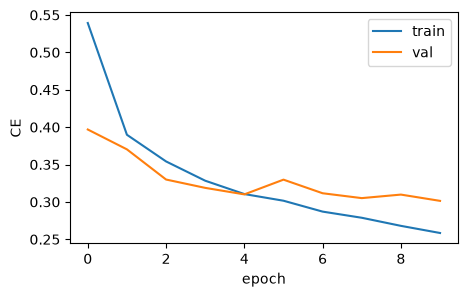

In [7]:
# 6. TRAIN. 10 epochs. Log per-epoch mean train loss, val loss, val acc into `history`
#    ("train_loss", "val_loss", "val_acc"). Keep the best-val-acc state_dict and load it at the end.
#    Plot the curves.
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_acc, best_state = -1.0, None
for epoch in range(10):
    model.train()
    run, n = 0.0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(dev), yb.to(dev)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        run += loss.item() * len(yb)
        n += len(yb)
    vl, va = evaluate(model, val_dl)
    for k, v in zip(history, (run / n, vl, va)):
        history[k].append(v)
    if va > best_acc:
        best_acc, best_state = va, {k: v.detach().clone() for k, v in model.state_dict().items()}
    print(f"epoch {epoch + 1:2d} train {run / n:.3f} val {vl:.3f} acc {va:.4f}")
model.load_state_dict(best_state)
plt.figure(figsize=(5, 3))
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("CE"); plt.legend(); plt.show()

test acc 0.8851
T-shirt/top  recall 0.811
Trouser      recall 0.961
Pullover     recall 0.787
Dress        recall 0.894
Coat         recall 0.833
Sandal       recall 0.963
Shirt        recall 0.735
Sneaker      recall 0.962
Bag          recall 0.965
Ankle boot   recall 0.940
most confused (true -> pred): T-shirt/top -> Shirt 142


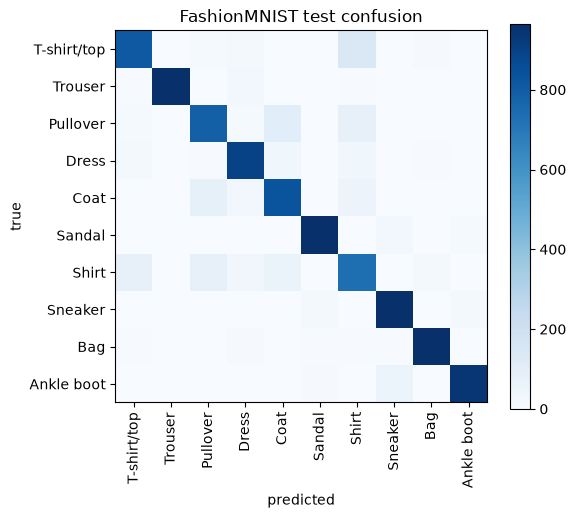

In [8]:
# 7. CONFUSION MATRIX BY HAND. `confusion(y_true, y_pred, num_classes) -> (C, C) int64 tensor`,
#    rows = TRUE class, columns = PREDICTED class, using ONE torch.bincount on num_classes * y_true + y_pred
#    (minlength = C*C so absent classes still get rows), then reshape.
#    Then: test predictions (touch test once) -> `test_acc`, `cm = confusion(y_test, test_pred, 10)`,
#    per-class recall (diag / row sums), the most-confused off-diagonal pair `worst_pair = (true, pred)`.
#    Plot cm with imshow + class names.
def confusion(y_true, y_pred, num_classes):
    idx = num_classes * y_true.long() + y_pred.long()
    return torch.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)


test_pred, test_true = predict(model, test_dl)
test_acc = (test_pred == test_true).float().mean().item()
cm = confusion(test_true, test_pred, 10)
recall = cm.diag() / cm.sum(1)
off = cm.clone().fill_diagonal_(0)
worst_pair = divmod(off.argmax().item(), 10)
print(f"test acc {test_acc:.4f}")
for c in range(10):
    print(f"{CLASSES[c]:12s} recall {recall[c]:.3f}")
print("most confused (true -> pred):", CLASSES[worst_pair[0]], "->", CLASSES[worst_pair[1]], off.max().item())
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.title("FashionMNIST test confusion")
plt.show()

## Self-check
Expects: `mu`, `X_train`, `y_train`, `model`, `init_loss`, `overfit_loss`, `history`, `confusion`, `cm`,
`test_pred`, `test_acc`, `worst_pair`, `evaluate`, `val_dl`.

In [9]:
from sklearn.metrics import confusion_matrix as sk_cm

check("labels are int64 class indices", y_train.dtype == torch.long and y_train.ndim == 1)
check("normalized with train stats", abs(X_train.mean().item()) < 1e-3 and abs(X_train.std().item() - 1) < 1e-3, "train mean/std should be ~0/1")
check("model returns (B, 10) logits", model(X_train[:3].to(dev)).shape == (3, 10))
check("no Softmax in model", not any(isinstance(m, (nn.Softmax, nn.LogSoftmax)) for m in model.modules()))
check("initial loss ~ ln 10", abs(init_loss - math.log(10)) < 0.2, f"got {init_loss:.3f}")
check("can overfit one batch", overfit_loss < 0.05, f"got {overfit_loss:.4f}")
g = torch.Generator().manual_seed(1)
yt, yp = torch.randint(0, 6, (500,), generator=g), torch.randint(0, 6, (500,), generator=g)
yt[yt == 5] = 4  # class 5 never appears as a TRUE label: needs minlength
check("confusion == sklearn (random, missing class)",
      np.array_equal(confusion(yt, yp, 6).cpu().numpy(), sk_cm(yt, yp, labels=range(6))), "rows=true, cols=pred, minlength=C*C")
check("confusion == sklearn on test", np.array_equal(cm.cpu().numpy(), sk_cm(y_test.numpy(), test_pred.numpy(), labels=range(10))))
check("rows sum to true class counts", torch.equal(cm.sum(1).cpu(), torch.bincount(y_test, minlength=10)))
check_close("trace / N == test accuracy", cm.diag().sum().item() / cm.sum().item(), test_acc)
check("most-confused pair is off-diagonal", worst_pair[0] != worst_pair[1])
check("val accuracy > 0.85", max(history["val_acc"]) > 0.85, f"got {max(history['val_acc']):.3f}")
check("eval deterministic (dropout off)", evaluate(model, val_dl) == evaluate(model, val_dl))
check("test accuracy > 0.85", test_acc > 0.85, f"got {test_acc:.3f}")

ok  labels are int64 class indices
ok  normalized with train stats
ok  model returns (B, 10) logits
ok  no Softmax in model
ok  initial loss ~ ln 10
ok  can overfit one batch
ok  confusion == sklearn (random, missing class)
ok  confusion == sklearn on test
ok  rows sum to true class counts
ok  trace / N == test accuracy
ok  most-confused pair is off-diagonal
ok  val accuracy > 0.85
ok  eval deterministic (dropout off)
ok  test accuracy > 0.85


## Say it out loud (P3)
1. Why is the initial loss ≈ ln 10 ≈ 2.30? What does an initial *accuracy* of ~10 % confirm?
2. Why compute the eval loss with `reduction="sum"` (or weight by batch size) and divide by N at the end?
3. Rows vs columns of the confusion matrix: what are row-normalized and column-normalized entries called?
4. Which classes get confused and why (look at the matrix)? What would you change in the model to fix it?
5. Why carve val out of train instead of using the test set for model selection?
6. Why must `CrossEntropyLoss` targets be `long` of shape (N,)? What happens if you pass float one-hot targets?
7. Where would a CNN beat this MLP, and why (inductive bias)?

<details><summary>Model answers</summary>

1. Default init gives small logits, so the softmax is close to uniform and CE = −log(1/10) = ln 10. Accuracy near
   10 % (chance) confirms the labels are balanced and the model isn't accidentally peeking at the labels. A much
   lower initial loss would suggest leakage.
2. The last batch can be smaller (here 5000 = 4·1024 + 904). A mean of per-batch means gives those examples more
   weight. Summing and dividing by N gives the exact dataset mean. Non-decomposable metrics (F1, AUC) need the
   aggregated predictions anyway.
3. Rows are true labels and columns are predictions (sklearn's convention). Row-normalized diagonal = per-class
   **recall**. Column-normalized diagonal = per-class **precision**. Say the convention out loud: libraries differ.
4. Shirt ↔ T-shirt/top, Pullover ↔ Coat and Shirt ↔ Coat dominate. They are upper-body garments whose
   silhouettes are very similar at 28×28. A CNN
   (local texture/edge features), augmentation, or more capacity helps. The Shirt class stays the hardest even
   for strong models.
5. If you pick hyperparameters or checkpoints on the test set, the test score is no longer an unbiased estimate of
   generalization (you overfit to it). Val is for decisions. Test is for one final report.
6. CE indexes the log-softmax with the class index (`gather`), so it needs integer indices. Since PyTorch 1.10,
   `CrossEntropyLoss` also accepts float **class probabilities** of shape (N, C) (soft labels). One-hot floats
   then give the same value, but (N,) floats raise a dtype error. Passing probabilities by accident (e.g. with
   label smoothing done twice) is a silent bug.
7. An MLP on flattened pixels has no notion of locality or translation equivariance: it must learn every shifted
   version of an edge separately. Convolutions share weights across positions. That gives far fewer parameters
   and better sample efficiency on images. In the Fashion-MNIST README benchmark, small 2-3-conv-layer CNNs reach
   0.90-0.94, against 0.883 for an MLP 256-128-100.
</details>

In [10]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.2] done in 0.2 min (within target 25 min)


0.22575327157974243